### 03. Retensi Pelanggan per Kohort

**Pertanyaan bisnis:** 

    berapa persen pelanggan yang kembali membeli di bulan-bulan berikutnya setelah pembelian pertama mereka?

**Istilah:**
- **Kohort:** Kelompok pelanggan yang melakukan pembelian pertama pada bulan yang sama.
- **Indeks bulan:** Jarak waktu dari bulan pembelian pertama. Bulan 0 adalah bulan pertama, bulan 1 adalah bulan berikutnya, dan seterusnya.
- **Retensi:** Persentase pelanggan yang kembali berbelanja pada bulan tertentu setelah pembelian pertama.

**Data yang Digunakan:**
data/processed/pelanggan.csv

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.1f}".format)

DATA_PROCESSED = Path("..") / "data" / "processed"
OUT = Path("..") / "outputs"
OUT.mkdir(exist_ok=True)

pelanggan = pd.read_csv(
    DATA_PROCESSED / "pelanggan.csv",
    dtype={"Invoice": "string", "StockCode": "string", "Customer ID": "string"},
    parse_dates=["InvoiceDate"],
)
print(pelanggan.shape)

(776596, 9)


**1. Siapkan data transaksi per invoice**

Data disusun berdasarkan pelanggan dan invoice, sehingga setiap transaksi dihitung satu kali, bukan per barang. Bulan terakhir dikeluarkan karena datanya belum lengkap agar hasil retensi tidak terlihat lebih rendah dari kondisi sebenarnya.

In [2]:
transaksi = (pelanggan.drop_duplicates(["Customer ID", "Invoice"])
             [["Customer ID", "Invoice", "InvoiceDate"]]
             .rename(columns={"Customer ID": "customer_id"}))

tgl_akhir = transaksi["InvoiceDate"].max()
bulan_terakhir = tgl_akhir.to_period("M")
if not tgl_akhir.is_month_end:
    print(f"Bulan {bulan_terakhir} tidak lengkap (data berakhir {tgl_akhir.date()}), dikeluarkan.")
    bulan_terakhir = bulan_terakhir - 1
print("Bulan lengkap terakhir:", bulan_terakhir)

transaksi["bulan_order"] = transaksi["InvoiceDate"].dt.to_period("M")
transaksi = transaksi[transaksi["bulan_order"] <= bulan_terakhir].copy()
print("Invoice dipakai:", f"{len(transaksi):,}", "| Pelanggan:", f"{transaksi['customer_id'].nunique():,}")

Bulan 2011-12 tidak lengkap (data berakhir 2011-12-09), dikeluarkan.
Bulan lengkap terakhir: 2011-11
Invoice dipakai: 35,818 | Pelanggan: 5,824


**2. Tentukan kohort dan indeks bulan**

In [3]:
def ke_bulan(seri_periode):
    return seri_periode.dt.year * 12 + seri_periode.dt.month

transaksi["bulan_kohort"] = transaksi.groupby("customer_id")["bulan_order"].transform("min")
transaksi["indeks"] = ke_bulan(transaksi["bulan_order"]) - ke_bulan(transaksi["bulan_kohort"])

assert (transaksi["indeks"] >= 0).all()
transaksi[["customer_id", "bulan_kohort", "bulan_order", "indeks"]].head()

,customer_id,bulan_kohort,bulan_order,indeks
0,13085,2009-12,2009-12,0
8,13085,2009-12,2009-12,0
12,13078,2009-12,2009-12,0
31,15362,2009-12,2009-12,0
54,18102,2009-12,2009-12,0


**3. Hitung retensi**

Sel yang **belum bisa diamati** (kohort terlalu baru untuk indeks bulan itu) dikosongkan, bukan dianggap 0%.

In [ ]:
aktif = (transaksi.groupby(["bulan_kohort", "indeks"])["customer_id"]
         .nunique().unstack(fill_value=0))
aktif = aktif.reindex(columns=range(int(aktif.columns.max()) + 1), fill_value=0)
ukuran = aktif[0]

# ukuran kohort = jumlah pelanggan unik di kohort tersebut
cek = transaksi.groupby("bulan_kohort")["customer_id"].nunique()
assert (cek.reindex(ukuran.index) == ukuran).all()
kohort_int = np.array([p.year * 12 + p.month for p in aktif.index])
akhir_int = bulan_terakhir.year * 12 + bulan_terakhir.month
bisa = pd.DataFrame(
    (kohort_int[:, None] + aktif.columns.to_numpy()[None, :]) <= akhir_int,
    index=aktif.index, columns=aktif.columns,
)

retensi = (aktif.div(ukuran, axis=0) * 100).where(bisa)
print("Jumlah kohort:", len(retensi), "| Indeks bulan terjauh:", retensi.columns.max())

Jumlah kohort: 24 | Indeks bulan terjauh: 23


**4. Retensi rata-rata (berbobot ukuran kohort)**

Kohort pada bulan pertama dihitung secara terpisah karena data baru dimulai pada Desember 2009. Akibatnya, pelanggan lama yang berbelanja pada bulan tersebut bisa dianggap sebagai pelanggan baru, sehingga jumlah pelanggan dan tingkat retensinya terlihat lebih tinggi dari sebenarnya.

In [5]:
def retensi_rata2(mask_kohort):
    a = aktif[mask_kohort]
    u = ukuran[mask_kohort]
    b = bisa[mask_kohort]
    pembilang = a.where(b).sum()
    penyebut = b.mul(u, axis=0).sum().replace(0, np.nan)
    return pembilang / penyebut * 100

semua = pd.Series(True, index=aktif.index)
tanpa_awal = pd.Series(aktif.index != aktif.index.min(), index=aktif.index)

ringkas = pd.DataFrame({
    "semua kohort": retensi_rata2(semua),
    f"tanpa kohort {aktif.index.min()}": retensi_rata2(tanpa_awal),
})
bulan_tampil = [k for k in (1, 2, 3, 6, 9, 12) if k in ringkas.index]
print("Retensi rata-rata (%) pada bulan ke-n setelah pembelian pertama:")
ringkas.loc[bulan_tampil]

Retensi rata-rata (%) pada bulan ke-n setelah pembelian pertama:


,semua kohort,tanpa kohort 2009-12
indeks,,
1,23.3,21.0
2,23.6,21.5
3,25.0,21.1
6,22.2,18.4
9,19.4,15.0
12,22.7,18.4


**5. Heatmap retensi per kohort**

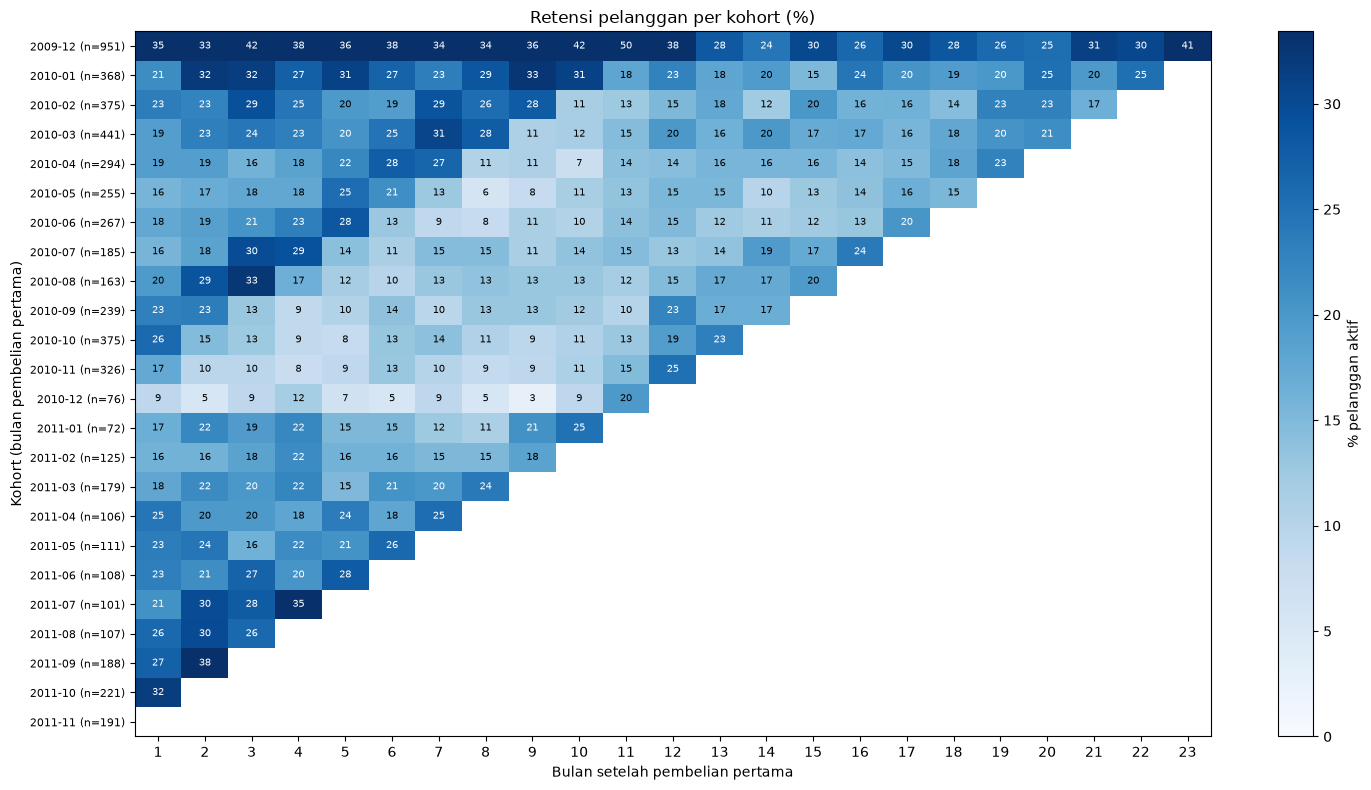

In [6]:
data = retensi.loc[:, 1:].to_numpy(dtype=float)
label_y = [f"{k} (n={int(ukuran[k]):,})" for k in retensi.index.astype(str)]

fig, ax = plt.subplots(figsize=(15, 8))
puncak = np.nanpercentile(data, 95)
im = ax.imshow(data, cmap="Blues", vmin=0, vmax=puncak, aspect="auto")

for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        v = data[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > puncak * 0.6 else "black")

ax.set_xticks(range(data.shape[1]))
ax.set_xticklabels(range(1, data.shape[1] + 1))
ax.set_yticks(range(len(label_y)))
ax.set_yticklabels(label_y, fontsize=8)
ax.set_xlabel("Bulan setelah pembelian pertama")
ax.set_ylabel("Kohort (bulan pembelian pertama)")
ax.set_title("Retensi pelanggan per kohort (%)")
fig.colorbar(im, ax=ax, label="% pelanggan aktif")
plt.tight_layout()
fig.savefig(OUT / "retensi_heatmap.png", dpi=150)
plt.show()

**6. Kurva retensi rata-rata**

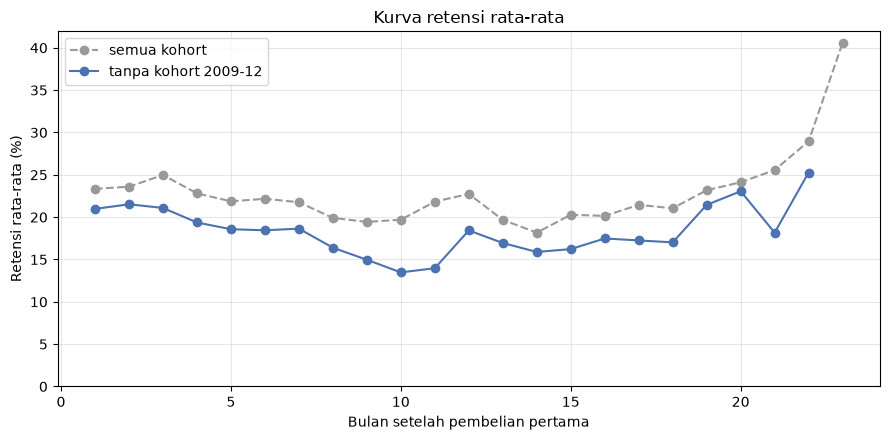

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
kurva = ringkas.loc[1:]
ax.plot(kurva.index, kurva.iloc[:, 0], marker="o", label=ringkas.columns[0], linestyle="--", color="#999999")
ax.plot(kurva.index, kurva.iloc[:, 1], marker="o", label=ringkas.columns[1], color="#4c72b0")
ax.set_xlabel("Bulan setelah pembelian pertama")
ax.set_ylabel("Retensi rata-rata (%)")
ax.set_title("Kurva retensi rata-rata")
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(OUT / "retensi_kurva.png", dpi=150)
plt.show()

In [9]:
print("Jumlah kohort yang bisa diamati pada bulan ke-n:")
print(bisa.sum().loc[[1, 3, 6, 9, 12, 18, 22, 23]])

Jumlah kohort yang bisa diamati pada bulan ke-n:
indeks
1     23
3     21
6     18
9     15
12    12
18     6
22     2
23     1
dtype: int64


**7. Temuan**

- **Temuan 1:** 

    Rata-rata 21% pelanggan kembali membeli pada bulan pertama setelah pembelian pertama mereka. Angka ini relatif stabil hingga bulan ketiga, lalu menurun menjadi 18,4% pada bulan keenam dan 15% pada bulan kesembilan.

- **Temuan 2:** 

    Pelanggan yang pertama kali membeli pada Desember 2010 memiliki tingkat retensi paling rendah, yaitu 9% pada bulan pertama. Hal ini menunjukkan bahwa pelanggan pada periode tersebut lebih sedikit yang kembali berbelanja dibandingkan beberapa kohort lainnya. Namun, diperlukan data tambahan untuk memastikan penyebabnya.

- **Temuan 3:** 

    Kohort Desember 2009 memiliki tingkat retensi yang tinggi. Namun, hasil ini mungkin dipengaruhi oleh pelanggan lama yang dianggap sebagai pelanggan baru karena data baru dimulai pada bulan tersebut.

**Keterbatasan:**

- Analisis hanya mencakup pelanggan yang memiliki ID dari satu toko grosir hadiah di Inggris pada periode 2009–2011.
- Bulan terakhir yang datanya belum lengkap dikeluarkan dari analisis.
- Kohort pertama mungkin mencakup pelanggan lama, sehingga hasilnya perlu ditafsirkan dengan hati-hati.
- Pelanggan dianggap aktif jika melakukan minimal satu transaksi dalam bulan tersebut, tanpa memperhitungkan jumlah belanja.

**8. Simpan hasil untuk dashboard**

In [8]:
panjang = (retensi.reset_index()
           .melt(id_vars="bulan_kohort", var_name="indeks", value_name="retensi_persen")
           .dropna())
panjang["bulan_kohort"] = panjang["bulan_kohort"].astype(str)
panjang["indeks"] = panjang["indeks"].astype(int)
ukuran_teks = ukuran.copy()
ukuran_teks.index = ukuran_teks.index.astype(str)
panjang["ukuran_kohort"] = panjang["bulan_kohort"].map(ukuran_teks)

panjang.to_csv(OUT / "kohort_retensi.csv", index=False)
ringkas.reset_index(names="indeks_bulan").to_csv(OUT / "kohort_retensi_rata2.csv", index=False)
print("Tersimpan di:", OUT.resolve())
print(sorted(p.name for p in OUT.iterdir()))

Tersimpan di: C:\Users\sarah\Documents\online-retail-customer-analysis\outputs
['kohort_retensi.csv', 'kohort_retensi_rata2.csv', 'retensi_heatmap.png', 'retensi_kurva.png', 'rfm_pelanggan.csv', 'rfm_ringkasan_segmen.csv', 'rfm_segmen.png']
